# Representativeness benchmarking and external validation

Datasets used here, all external to the main pipeline:

- BLS OES (Occupational Employment and Wage Statistics): national employment counts by detailed SOC code, 2012/2019/2022. Used to benchmark the sample's occupational composition against US employment, restricted to O*NET Job Zones 4-5.
- LEHD J2J (Job-to-Job Flows), US Census Bureau. Two extracts: state-to-state origin-destination flows with sex and education detail, 2011-2019, for the main flow validation; and a single-geography indicator table crossed with 21 NAICS sectors, 2019, as a secondary check on whether the sample tracks job-to-job activity in Professional/Technical and Information industries specifically.
- ACS educational attainment (table S1501), county level. Used to benchmark the sample's geographic distribution against where college-educated adults live, and its age profile against the BA-or-higher population.
- CBP (County Business Patterns), 2022: county establishment and employment counts, used alongside ACS population as a second, independent geographic benchmark.

## Setup

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ[_v] = "10"

import sys
sys.path.insert(0, ".")
import subprocess
import pandas as pd
import numpy as np
from utils import set_plot_style

REPO = ".."
set_plot_style()

git_sha = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                         capture_output=True, text=True).stdout.strip()
print("Repo HEAD:", git_sha)
print("Run timestamp:", pd.Timestamp.now())

Repo HEAD: 7636fab
Run timestamp: 2026-10-07 12:13:54.716611


## Section 1 - Occupational representativeness vs BLS OES

Compares our SOC-group shares against BLS OES employment shares restricted to O*NET Job Zones 4-5.
Uses the **origin** occupation (`soc_broad`, 1.8% null) rather than the destination
(`next_soc_broad`, 28.1% null).

In [2]:
import sqlite3
from utils import SOC2_MAP

df_win = pd.read_parquet(f"{REPO}/data_generated/df_win.parquet")
print(f"df_win: {len(df_win)} rows, {df_win.PERSON_ID.nunique()} persons")
print("Using ORIGIN occupation (Code_final/soc_broad): destination (next_soc_broad) is 28.1% null")
print(f"  soc_broad null share:      {df_win.soc_broad.isna().mean():.3%}")
print(f"  next_soc_broad null share: {df_win.next_soc_broad.isna().mean():.3%}")

df_win: 200421 rows, 128006 persons
Using ORIGIN occupation (Code_final/soc_broad): destination (next_soc_broad) is 28.1% null
  soc_broad null share:      1.836%
  next_soc_broad null share: 28.150%


### SOC6 -> Job Zone map: union of the `jobzone` table and an empirical map from df_win itself

In [3]:
con = sqlite3.connect(f"{REPO}/data_raw/NEW_MAIN.db")
jz = pd.read_sql("SELECT JOB_ONET_CODE, Job_Zone FROM jobzone", con)
jz["soc6"] = jz["JOB_ONET_CODE"].astype(str).str[:7]
jz_map = jz.groupby("soc6")["Job_Zone"].agg(lambda s: s.mode().iloc[0]).rename("zone_jobzone")
jz_base = jz[jz["JOB_ONET_CODE"].astype(str).str.endswith(".00")].set_index("soc6")["Job_Zone"].rename("zone_jobzone_base")
jz_map = jz_map.to_frame().join(jz_base, how="left")
jz_map["zone_jobzone_final"] = jz_map["zone_jobzone_base"].fillna(jz_map["zone_jobzone"])
n_conflict_jz = jz.groupby("soc6")["Job_Zone"].nunique()
print(f"jobzone table: {jz.JOB_ONET_CODE.nunique()} O*NET codes -> {jz.soc6.nunique()} SOC6, "
     f"{(n_conflict_jz > 1).sum()} SOC6 with conflicting Job_Zone across .XX variants")

df_win["soc6"] = df_win["Code_final"].astype(str).str[:7]
emp_map = (df_win.dropna(subset=["Job Zone_final", "soc6"])
          .groupby("soc6")["Job Zone_final"].agg(lambda s: s.mode().iloc[0]).rename("zone_empirical"))
print(f"empirical df_win map: {emp_map.shape[0]} SOC6 covered")

zone_map = jz_map[["zone_jobzone_final"]].join(emp_map, how="outer")
zone_map["zone_final"] = zone_map["zone_empirical"].fillna(zone_map["zone_jobzone_final"])
zone_map["zone_min"] = zone_map[["zone_jobzone_final", "zone_empirical"]].min(axis=1)
zone_map["provenance"] = np.where(zone_map["zone_empirical"].notna(), "empirical_df_win", "jobzone_table")
print(f"Union SOC6 -> Job Zone map: {zone_map.shape[0]} SOC6 total")

cov = df_win["soc6"].isin(zone_map.index).mean()
print(f"df_win rows whose SOC6 is covered by the union map: {cov:.1%}")

jobzone table: 265 O*NET codes -> 220 SOC6, 9 SOC6 with conflicting Job_Zone across .XX variants
empirical df_win map: 455 SOC6 covered
Union SOC6 -> Job Zone map: 486 SOC6 total
df_win rows whose SOC6 is covered by the union map: 98.2%


### BLS OES: keep detailed-level rows only

In [4]:
import zipfile

def load_oes(year_tag):
    zpath = f"{REPO}/data_loaded/external_validation/oesm{year_tag}nat.zip"
    with zipfile.ZipFile(zpath) as z:
        names = [n for n in z.namelist() if "national" in n.lower() and n.lower().endswith((".xlsx", ".xls"))]
        with z.open(names[0]) as f:
            df = pd.read_excel(f)
    df.columns = [c.lower() for c in df.columns]
    if "o_group" not in df.columns and "occ_group" in df.columns:
        df = df.rename(columns={"occ_group": "o_group"})
    return df

oes_results = {}
for tag, label in [("12", 2012), ("19", 2019), ("22", 2022)]:
    oes = load_oes(tag)
    total_row = oes[(oes["occ_code"] == "00-0000")]
    oes_detail = oes[oes["o_group"].str.lower() == "detailed"].copy()
    oes_detail["tot_emp"] = pd.to_numeric(oes_detail["tot_emp"], errors="coerce")
    n_suppressed = oes_detail["tot_emp"].isna().sum()
    ratio_check = oes_detail["tot_emp"].sum() / pd.to_numeric(total_row["tot_emp"].iloc[0], errors="coerce")
    print(f"OES {label}: {len(oes)} raw rows -> {len(oes_detail)} detailed rows, "
         f"{n_suppressed} suppressed ({n_suppressed/len(oes_detail):.1%})")
    print(f"  detailed sum / 00-0000 total = {ratio_check:.4f}  (sanity check)")
    assert 0.90 < ratio_check < 1.10
    oes_results[label] = oes_detail

oes19 = oes_results[2019].copy()
oes19["soc6"] = oes19["occ_code"].astype(str)

OES 2012: 1394 raw rows -> 820 detailed rows, 0 suppressed (0.0%)
  detailed sum / 00-0000 total = 1.0000  (sanity check)
OES 2019: 1329 raw rows -> 789 detailed rows, 0 suppressed (0.0%)
  detailed sum / 00-0000 total = 1.0000  (sanity check)
OES 2022: 1402 raw rows -> 830 detailed rows, 0 suppressed (0.0%)
  detailed sum / 00-0000 total = 1.0000  (sanity check)


### Join to zone map, restrict to zones 4-5, aggregate to SOC2_MAP broad groups

In [5]:
oes19 = oes19.merge(zone_map[["zone_final", "zone_min"]], left_on="soc6", right_index=True, how="left")
unmatched = oes19["zone_final"].isna()
unmatched_emp_share = oes19.loc[unmatched, "tot_emp"].sum() / oes19["tot_emp"].sum()
print(f"OES 2019 SOC6 unmatched to zone map: {unmatched.sum()}/{len(oes19)} "
     f"({unmatched_emp_share:.1%} of national detailed employment)")

oes_jz45 = oes19[oes19["zone_final"].isin([4.0, 5.0])].copy()
oes_jz45_min = oes19[oes19["zone_min"].isin([4.0, 5.0])].copy()
print(f"OES 2019 employment, zones 4-5 (preferred-zone rule): {oes_jz45['tot_emp'].sum():,.0f}")
print(f"OES 2019 employment, zones 4-5 (min-zone rule):        {oes_jz45_min['tot_emp'].sum():,.0f}")

oes_jz45["soc2"] = oes_jz45["occ_code"].astype(str).str[:2]
oes_jz45["soc_broad"] = oes_jz45["soc2"].map(SOC2_MAP)
oes_by_group = oes_jz45.groupby("soc_broad")["tot_emp"].sum().rename("oes_emp")

our_groups = set(df_win["soc_broad"].dropna().unique())
oes_groups = set(oes_by_group.index.dropna())
print(f"soc_broad groups in our sample: {len(our_groups)}")
print(f"soc_broad groups in OES JZ4-5:  {len(oes_groups)}")
missing_in_oes = our_groups - oes_groups
print(f"our groups absent from OES (become zero rows): {missing_in_oes}")

OES 2019 SOC6 unmatched to zone map: 370/789 (30.7% of national detailed employment)
OES 2019 employment, zones 4-5 (preferred-zone rule): 35,163,820
OES 2019 employment, zones 4-5 (min-zone rule):        34,944,290
soc_broad groups in our sample: 21
soc_broad groups in OES JZ4-5:  15
our groups absent from OES (become zero rows): {'Cleaning', 'Installation & Repair', 'Production', 'Healthcare Support', 'Construction', 'Food Service'}


30.7% of national OES employment does not match the Job Zone map, so the ratios below are computed on the matched subset only.

In [6]:
our_persons = df_win.drop_duplicates("PERSON_ID").groupby("soc_broad").size().rename("n_persons")
our_transitions = df_win.groupby("soc_broad").size().rename("n_transitions")

comparison = pd.concat([our_persons, our_transitions, oes_by_group], axis=1).reindex(
    sorted(our_groups | oes_groups)).fillna(0)
comparison["our_share_persons"] = comparison["n_persons"] / comparison["n_persons"].sum()
comparison["our_share_transitions"] = comparison["n_transitions"] / comparison["n_transitions"].sum()
comparison["oes_share"] = comparison["oes_emp"] / comparison["oes_emp"].sum()
comparison["ratio_persons"] = comparison["our_share_persons"] / comparison["oes_share"]
comparison["log2_ratio_persons"] = np.log2(comparison["ratio_persons"].replace(0, np.nan))
comparison.to_csv(f"{REPO}/data_generated/representativeness/occupational_coverage.csv")

In [7]:
comparison[["n_persons", "n_transitions", "oes_emp", "our_share_persons", "oes_share",
                  "ratio_persons", "log2_ratio_persons"]].round(4)

,n_persons,n_transitions,oes_emp,our_share_persons,oes_share,ratio_persons,log2_ratio_persons
soc_broad,,,,,,,
Architecture & Engineering,1992,2823,1953280.0,0.0160,0.0555,0.2873,-1.7992
Arts / Media / Design,8996,14413,1380250.0,0.0721,0.0393,1.8363,0.8768
Business & Finance,19494,30037,5801810.0,0.1562,0.1650,0.9467,-0.0791
Cleaning,3,3,0.0,0.0000,0.0000,inf,inf
Computer & Math,34386,58577,1605010.0,0.2755,0.0456,6.0361,2.5936
Construction,10,11,0.0,0.0001,0.0000,inf,inf
Education / Training,8416,12127,5793360.0,0.0674,0.1648,0.4093,-1.2888
Food Service,52,53,0.0,0.0004,0.0000,inf,inf
Healthcare Practitioners,1885,3104,4851970.0,0.0151,0.1380,0.1095,-3.1916


Computer & Math is 6.0x overrepresented relative to its OES JZ4-5 employment share (27.6% of persons vs 4.6% of OES employment). Healthcare Practitioners is 0.11x - strongly underrepresented (1.5% vs 13.8%). Six of our 21
soc_broad groups have essentially zero matching OES JZ4-5 employment (Cleaning, Construction, Food Service, Healthcare Support, Installation & Repair, Production) - these are occupations whose *origin* job falls outside Job Zone 4-5 even though the *destination* job (which defines sample inclusion) is JZ4-5: potentially an upward career transitions from lower-zone origin jobs.

### Sensitivity: preferred-zone vs min-zone assignment rule

In [8]:
oes_jz45_min["soc2"] = oes_jz45_min["occ_code"].astype(str).str[:2]
oes_jz45_min["soc_broad"] = oes_jz45_min["soc2"].map(SOC2_MAP)
oes_by_group_min = oes_jz45_min.groupby("soc_broad")["tot_emp"].sum().rename("oes_emp_minzone")
comp_min = pd.concat([our_persons, oes_by_group_min], axis=1).reindex(sorted(our_groups | oes_groups)).fillna(0)
comp_min["oes_share_min"] = comp_min["oes_emp_minzone"] / comp_min["oes_emp_minzone"].sum()
comp_min["ratio_min"] = (comp_min["n_persons"] / comp_min["n_persons"].sum()) / comp_min["oes_share_min"]

move = (comparison["ratio_persons"] - comp_min["ratio_min"]).abs()
print(f"Sensitivity (preferred-zone vs min-zone rule): mean |ratio diff| = {move.mean():.4f}, "
     f"max = {move.max():.4f} ({move.idxmax()})")

Sensitivity (preferred-zone vs min-zone rule): mean |ratio diff| = 0.0485, max = 0.5917 (Computer & Math)


### Vintage stability: OES 2012 vs 2019 vs 2022

In [9]:
vintage_ratios = {}
for label, oes_y in oes_results.items():
    oes_y2 = oes_y.copy()
    oes_y2["soc6"] = oes_y2["occ_code"].astype(str)
    oes_y2 = oes_y2.merge(zone_map[["zone_final"]], left_on="soc6", right_index=True, how="left")
    oes_y2_jz45 = oes_y2[oes_y2["zone_final"].isin([4.0, 5.0])].copy()
    oes_y2_jz45["soc2"] = oes_y2_jz45["occ_code"].astype(str).str[:2]
    oes_y2_jz45["soc_broad"] = oes_y2_jz45["soc2"].map(SOC2_MAP)
    g = oes_y2_jz45.groupby("soc_broad")["tot_emp"].sum()
    vintage_ratios[label] = g / g.sum()
vint_df = pd.DataFrame(vintage_ratios).reindex(sorted(our_groups | oes_groups)).fillna(0)
vint_df["our_share_persons"] = comparison["our_share_persons"]
print(vint_df.round(4).to_string())
print("\nNote: SOC taxonomy revised 2010->2018, breaking continuity for major groups 15/19/27/29.")

                              2012    2019    2022  our_share_persons
soc_broad                                                            
Architecture & Engineering  0.0576  0.0555  0.0434             0.0160
Arts / Media / Design       0.0384  0.0393  0.0328             0.0721
Business & Finance          0.2032  0.1650  0.2076             0.1562
Cleaning                    0.0000  0.0000  0.0000             0.0000
Computer & Math             0.0040  0.0456  0.0858             0.2755
Construction                0.0000  0.0000  0.0000             0.0001
Education / Training        0.1517  0.1648  0.1284             0.0674
Food Service                0.0000  0.0000  0.0000             0.0004
Healthcare Practitioners    0.1356  0.1380  0.1285             0.0151
Healthcare Support          0.0000  0.0000  0.0000             0.0011
Installation & Repair       0.0000  0.0000  0.0000             0.0004
Legal                       0.0214  0.0206  0.0178             0.0055
Management          

In [10]:
print(f"OES 2019 raw rows: {len(load_oes('19'))}")
print(f"-> detailed only (O_GROUP filter): {len(oes19)}")
print(f"-> unmatched to zone map: {unmatched.sum()} ({unmatched_emp_share:.1%} of employment)")
print(f"-> restricted to zones 4-5: {len(oes_jz45)}")
print(f"df_win soc_broad nulls: {df_win.soc_broad.isna().sum()} ({df_win.soc_broad.isna().mean():.2%})")
print(f"our soc_broad groups absent from OES JZ4-5 (zero rows): {len(missing_in_oes)}")

OES 2019 raw rows: 1329
-> detailed only (O_GROUP filter): 789
-> unmatched to zone map: 370 (30.7% of employment)
-> restricted to zones 4-5: 236
df_win soc_broad nulls: 3679 (1.84%)
our soc_broad groups absent from OES JZ4-5 (zero rows): 6


## Section 2 - Geographic representativeness

Correlates CBSA-level our record counts against ACS BA+ population and CBP employment, and maps over/under-coverage.

In [11]:
from utils import load_cbsa

cbsa_xwalk = load_cbsa(path=f"{REPO}/data_loaded/cbsa_2023.xlsx")[["STCOFIPS", "CBSA Code"]].drop_duplicates()
df_win2 = df_win.merge(cbsa_xwalk, on="STCOFIPS", how="left")
n_unmatched = df_win2["CBSA Code"].isna().sum()
print(f"df_win rows unmatched to a CBSA (non-metro county): {n_unmatched} ({n_unmatched/len(df_win2):.2%})")
df_win2 = df_win2.dropna(subset=["CBSA Code"])

our_persons_geo = df_win2.drop_duplicates("PERSON_ID").groupby("CBSA Code").size().rename("n_persons")
our_transitions_geo = df_win2.groupby("CBSA Code").size().rename("n_transitions")

df_merged = pd.read_csv(f"{REPO}/data_generated/df_merged_cbsa2.csv", index_col=0)
df_merged["CBSA"] = df_merged["CBSA"].astype(str)
print(f"df_merged_cbsa2.csv: {len(df_merged)} CBSAs, has existing emp column: {'emp' in df_merged.columns}")

df_win rows unmatched to a CBSA (non-metro county): 4131 (2.06%)
df_merged_cbsa2.csv: 698 CBSAs, has existing emp column: True


In [12]:
import zipfile

with zipfile.ZipFile(f"{REPO}/data_loaded/cbp22co.zip") as z:
    names = z.namelist()
    with z.open(names[0]) as f:
        cbp = pd.read_csv(f, dtype=str, low_memory=False)
cbp.columns = [c.lower() for c in cbp.columns]
cbp_tot = cbp[cbp["naics"].astype(str).str.strip() == "------"].copy()
cbp_tot["emp"] = pd.to_numeric(cbp_tot["emp"], errors="coerce")
cbp_tot["STCOFIPS"] = cbp_tot["fipstate"].str.zfill(2) + cbp_tot["fipscty"].str.zfill(3)
cbp_cbsa = cbp_tot.merge(cbsa_xwalk, on="STCOFIPS", how="left").dropna(subset=["CBSA Code"])
cbp_emp_by_cbsa = cbp_cbsa.groupby("CBSA Code")["emp"].sum()

### ACS BA+ population (county -> CBSA)

In [13]:
edu = pd.read_parquet(f"{REPO}/data_loaded/data_final/education_combined.parquet")
print(f"education_combined.parquet: {len(edu)} rows, years present: {sorted(edu.year.unique())}")
print("Single cross-sectional year (ACS 2016-2020 5-year estimate) -- not a 2011-2019 panel as")
print("initially planned. Using it as-is: a static BA+ population benchmark, not period-matched")
print("to the paper's full 2011-2022 sample window.")
edu["ba_plus"] = edu["ba_degree_total"] + edu["grad_degree_total"]
edu_cbsa = edu[["STCOFIPS", "ba_plus"]].merge(cbsa_xwalk, on="STCOFIPS", how="left").dropna(subset=["CBSA Code"])
ba_by_cbsa = edu_cbsa.groupby("CBSA Code")["ba_plus"].sum().rename("ba_plus_pop")

education_combined.parquet: 3140 rows, years present: ['2020']
Single cross-sectional year (ACS 2016-2020 5-year estimate) -- not a 2011-2019 panel as
initially planned. Using it as-is: a static BA+ population benchmark, not period-matched
to the paper's full 2011-2022 sample window.


### Build the comparison table and statistics

In [14]:
import statsmodels.api as sm
from scipy import stats

geo = pd.concat([our_persons_geo, our_transitions_geo], axis=1).fillna(0)
geo.index = geo.index.astype(str)
geo = geo.join(ba_by_cbsa, how="left")
geo = geo.join(cbp_emp_by_cbsa.rename("emp"), how="left")
geo = geo.dropna(subset=["ba_plus_pop", "emp"])
print(f"Geographic comparison table: {len(geo)} CBSAs with all three measures present")

def loglog_stats(x, y):
    mask = (x > 0) & (y > 0) & x.notna() & y.notna()
    lx, ly = np.log10(x[mask] + 1), np.log10(y[mask] + 1)
    pear = stats.pearsonr(lx, ly)
    spear = stats.spearmanr(x[mask], y[mask])
    X = sm.add_constant(lx)
    m = sm.OLS(ly, X).fit()
    slope = m.params.iloc[1]
    ci = m.conf_int().iloc[1]
    return dict(pearson_loglog=pear[0], spearman=spear.correlation, slope=slope,
               slope_ci_lo=ci[0], slope_ci_hi=ci[1], n=mask.sum())

rows = []
for our_col, our_lbl in [("n_persons", "persons"), ("n_transitions", "transitions")]:
    for bench_col, bench_lbl in [("ba_plus_pop", "BA+ population"), ("emp", "CBP employment")]:
        r = loglog_stats(geo[our_col], geo[bench_col])
        r["our"] = our_lbl
        r["benchmark"] = bench_lbl
        rows.append(r)
stats_df = pd.DataFrame(rows)[["our", "benchmark", "pearson_loglog", "spearman", "slope", "slope_ci_lo", "slope_ci_hi", "n"]]
print(stats_df.round(4).to_string(index=False))

Geographic comparison table: 845 CBSAs with all three measures present
        our      benchmark  pearson_loglog  spearman  slope  slope_ci_lo  slope_ci_hi   n
    persons BA+ population          0.9067    0.8364 0.7359       0.7122       0.7595 812
    persons CBP employment          0.8956    0.8204 0.6853       0.6618       0.7088 812
transitions BA+ population          0.9155    0.8557 0.7129       0.6917       0.7341 845
transitions CBP employment          0.9052    0.8406 0.6634       0.6424       0.6845 845


### Over/under-coverage residuals

In [15]:
mask = (geo["n_persons"] > 0) & (geo["ba_plus_pop"] > 0)
geo_m = geo[mask].copy()
geo_m["log_persons"] = np.log10(geo_m["n_persons"] + 1)
geo_m["log_ba"] = np.log10(geo_m["ba_plus_pop"] + 1)
X = sm.add_constant(geo_m["log_ba"])
resid_model = sm.OLS(geo_m["log_persons"], X).fit()
geo_m["coverage_residual"] = resid_model.resid

cbsa_titles = load_cbsa(path=f"{REPO}/data_loaded/cbsa_2023.xlsx")[["CBSA Code", "CBSA Title"]].drop_duplicates("CBSA Code").set_index("CBSA Code")
geo_m = geo_m.join(cbsa_titles, how="left")

print("Top/bottom lists restricted to CBSAs with above-median BA+ population (avoids small-N noise):")
geo_large = geo_m[geo_m["ba_plus_pop"] >= geo_m["ba_plus_pop"].median()]
print(f"\nTop 10 over-covered, BA+ population >= median ({geo_m['ba_plus_pop'].median():,.0f}), n={len(geo_large)}:")
print(geo_large.sort_values("coverage_residual", ascending=False)[["CBSA Title", "n_persons", "ba_plus_pop", "coverage_residual"]].head(10).to_string(index=False))
print("\nTop 10 under-covered, BA+ population >= median:")
print(geo_large.sort_values("coverage_residual")[["CBSA Title", "n_persons", "ba_plus_pop", "coverage_residual"]].head(10).to_string(index=False))

per1000 = (geo_m["n_persons"] / geo_m["ba_plus_pop"] * 1000)
print(f"\nPDL persons per 1,000 BA+ adults: median={per1000.median():.2f}, "
     f"p10={per1000.quantile(.1):.2f}, p90={per1000.quantile(.9):.2f}")

geo_m[["n_persons", "n_transitions", "ba_plus_pop", "emp", "coverage_residual"]].to_csv(
    f"{REPO}/data_generated/representativeness/geographic_coverage.csv")

Top/bottom lists restricted to CBSAs with above-median BA+ population (avoids small-N noise):

Top 10 over-covered, BA+ population >= median (14,732), n=406:
                        CBSA Title  n_persons  ba_plus_pop  coverage_residual
San Jose-Sunnyvale-Santa Clara, CA     4751.0     724975.0           0.733038
                        Ithaca, NY      143.0      31848.0           0.730971
               Provo-Orem-Lehi, UT      683.0     128781.0           0.729725
                   Bloomington, IN      157.0      40903.0           0.649848
                          Ames, IA      113.0      31534.0           0.634322
                        Monroe, LA      112.0      32356.0           0.618009
                      Logan, UT-ID       83.0      26086.0           0.593728
                   Bloomington, IL      156.0      46806.0           0.581677
                    Eau Claire, WI      101.0      32072.0           0.577808
                  Cedar Rapids, IA      195.0      58579.0    

## Section 3 - Demographic representativeness

Infers age two ways: the existing `age` field (career-start based) and a graduation-year-derived proxy from `education.END_DATE`. Compares both against the ACS 2019 BA+ population age distribution (S1501, true age-by-education-attainment cross, county-level source).

In [16]:
n_total = len(df_win)
n_missing = df_win["age"].isna().sum()
print(f"Base A -- existing `age` field (18 + years since earliest education start)")
print(f"  missing: {n_missing}/{n_total} ({n_missing/n_total:.2%})")
valid = df_win["age"].dropna()
below18 = (valid < 18).sum()
above70 = (valid > 70).sum()
print(f"  of non-missing: below 18 clipped: {below18} ({below18/len(valid):.2%}), "
     f"above 70 clipped: {above70} ({above70/len(valid):.2%})")
age_a = valid.clip(18, 70)

Base A -- existing `age` field (18 + years since earliest education start)
  missing: 64175/200421 (32.02%)
  of non-missing: below 18 clipped: 6526 (4.79%), above 70 clipped: 59 (0.04%)


In [17]:
con = sqlite3.connect(f"{REPO}/data_raw/NEW_MAIN.db")
edu_raw = pd.read_sql("SELECT EDUCATION_ID, END_DATE AS GRAD_END_DATE FROM education", con)
print(f"education table: {len(edu_raw)} rows, {edu_raw.EDUCATION_ID.nunique()} unique EDUCATION_ID")
edu_dedup = edu_raw.drop_duplicates("EDUCATION_ID")
print(f"  after drop_duplicates('EDUCATION_ID'): {len(edu_dedup)} rows")
print("  (renamed education.END_DATE -> GRAD_END_DATE: df_win already has its own END_DATE,")
print("  the job EXPERIENCE end date -- an unrenamed merge would silently collide/suffix it)")

n_before = len(df_win)
df_b = df_win.merge(edu_dedup, on="EDUCATION_ID", how="left")
n_after = len(df_b)
assert n_before == n_after, f"MERGE TRAP: row count changed {n_before} -> {n_after}"
print(f"  merge row-count check: {n_before} -> {n_after} (unchanged, assertion passed)")

df_b["grad_year"] = pd.to_numeric(df_b["GRAD_END_DATE"], errors="coerce")
df_b["career_age_proxy"] = 22 + (df_b["next_start_date"].dt.year - df_b["grad_year"])
n_missing_b = df_b["career_age_proxy"].isna().sum()
print(f"  missing (no matched EDUCATION_ID or bad year): {n_missing_b}/{len(df_b)} ({n_missing_b/len(df_b):.2%})")
age_b = df_b["career_age_proxy"].dropna().clip(18, 70)

education table: 866529 rows, 866529 unique EDUCATION_ID
  after drop_duplicates('EDUCATION_ID'): 866529 rows
  (renamed education.END_DATE -> GRAD_END_DATE: df_win already has its own END_DATE,
  the job EXPERIENCE end date -- an unrenamed merge would silently collide/suffix it)
  merge row-count check: 200421 -> 200421 (unchanged, assertion passed)
  missing (no matched EDUCATION_ID or bad year): 54249/200421 (27.07%)


In [18]:
both = pd.DataFrame({"age_a": df_win["age"], "age_b": df_b["career_age_proxy"]}).dropna()
rho, p = stats.spearmanr(both["age_a"], both["age_b"])
print(f"Spearman(Base A, Base B) on {len(both)} rows with both present: rho={rho:.3f}, p={p:.2e}")
print(f"Base A median={both['age_a'].median():.1f}, Base B median={both['age_b'].median():.1f}")

Spearman(Base A, Base B) on 18517 rows with both present: rho=0.010, p=1.56e-01
Base A median=26.1, Base B median=27.0


The two age proxies are effectively uncorrelated at the individual level (Spearman rho = 0.010, p = 0.156, n = 18,517), so neither is a person-level age measure. They are used only for the aggregate comparison below.

### ACS 2019 S1501 BA+ population age distribution (true age x education-attainment cross, county-level source)

In [19]:
with zipfile.ZipFile(f"{REPO}/data_loaded/data_final/ACSST1Y2010.S1501.zip") as z:
    names = [n for n in z.namelist() if "2019.S1501-Data.csv" in n]
    with z.open(names[0]) as f:
        s1501 = pd.read_csv(f, skiprows=[1], dtype=str)

age_cols = {"18-24": "S1501_C01_005E", "25-34": "S1501_C01_018E", "35-44": "S1501_C01_021E",
           "45-64": "S1501_C01_024E", "65+": "S1501_C01_027E"}
for c in age_cols.values():
    s1501[c] = pd.to_numeric(s1501[c], errors="coerce")
acs_totals = {label: s1501[col].sum() for label, col in age_cols.items()}
acs_dist = pd.Series(acs_totals)
acs_dist = acs_dist / acs_dist.sum()
print("ACS 2019 S1501 BA+ population age distribution (national, county-summed):")
print(acs_dist.round(4).to_string())

def bucket(ages):
    bins = [18, 25, 35, 45, 65, 200]
    labels = ["18-24", "25-34", "35-44", "45-64", "65+"]
    return pd.cut(ages, bins=bins, labels=labels, right=False)

dist_a = bucket(age_a).value_counts(normalize=True).reindex(acs_dist.index)
dist_b = bucket(age_b).value_counts(normalize=True).reindex(acs_dist.index)

compare = pd.DataFrame({"ACS_BA+_2019": acs_dist, "Base_A_age_field": dist_a, "Base_B_graduation_proxy": dist_b})
print()
print(compare.round(4).to_string())
compare.to_csv(f"{REPO}/data_generated/representativeness/demographic_comparison.csv")

ACS 2019 S1501 BA+ population age distribution (national, county-summed):
18-24    0.0471
25-34    0.2206
35-44    0.2027
45-64    0.3384
65+      0.1913

       ACS_BA+_2019  Base_A_age_field  Base_B_graduation_proxy
18-24        0.0471            0.4352                   0.3645
25-34        0.2206            0.3801                   0.4273
35-44        0.2027            0.1286                   0.1420
45-64        0.3384            0.0551                   0.0657
65+          0.1913            0.0011                   0.0005


In [20]:
chi2_a = ((dist_a - acs_dist) ** 2 / acs_dist).sum()
chi2_b = ((dist_b - acs_dist) ** 2 / acs_dist).sum()
print(f"Sum of squared relative deviations from ACS: Base A = {chi2_a:.4f}, Base B = {chi2_b:.4f}")
print(f"18-34 share: ours (Base A) = {dist_a[:2].sum():.3f}, ours (Base B) = {dist_b[:2].sum():.3f}, ACS = {acs_dist[:2].sum():.3f}")
agree = (dist_a[:2].sum() > acs_dist[:2].sum()) == (dist_b[:2].sum() > acs_dist[:2].sum())
print(f"Conclusion sensitivity: both bases show the same qualitative direction ({'consistent' if agree else 'DIVERGENT'})")

Sum of squared relative deviations from ACS: Base A = 3.7684, Base B = 2.7620
18-34 share: ours (Base A) = 0.815, ours (Base B) = 0.792, ACS = 0.268
Conclusion sensitivity: both bases show the same qualitative direction (consistent)


Despite the two age bases barely correlating at the individual level, they agree in aggregate: the sample skews heavily young relative to the ACS BA+ population(18-34 share ~0.79-0.82 vs 0.27 in ACS).

## Visual comparison: high-skill (exp) vs general-mobility (irs) CBSA networks

Reuses the AK/HI-inset choropleth pattern from `5_projections.ipynb` (cells 17-33) rather than
rewriting map code from scratch.

In [21]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from utils import load_counties

hits_exp = pd.read_parquet(f"{REPO}/data_generated/network_metrics/cbsa2_hits_exp_1122.parquet")
hits_irs = pd.read_parquet(f"{REPO}/data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")
print(f"hits_exp: {len(hits_exp)} CBSAs, hits_irs: {len(hits_irs)} CBSAs")

merged = hits_irs.merge(hits_exp, on="CBSA", how="inner", suffixes=("_irs", "_exp"))
merged["CBSA"] = merged["CBSA"].astype(str)
print(f"Common CBSAs: {len(merged)}")

merged["log_pagerank_exp"] = np.log(merged["pagerank_exp"])
merged["log_pagerank_irs"] = np.log(merged["pagerank_irs"])
merged["pagerank_logdiff"] = merged["log_pagerank_exp"] - merged["log_pagerank_irs"]

counties = load_counties(data_loaded=f"{REPO}/data_loaded")
cbsa = load_cbsa(path=f"{REPO}/data_loaded/cbsa_2023.xlsx")
counties_ = counties.merge(cbsa[["CBSA Code", "CBSA Title", "STCOFIPS"]], on="STCOFIPS", how="left")
cbsa_gdf = counties_.dissolve(by="CBSA Code", as_index=False)
cbsa_gdf = cbsa_gdf.rename(columns={"CBSA Title": "name", "CBSA Code": "CBSA"})
cbsa_gdf["CBSA"] = cbsa_gdf["CBSA"].astype(str)

cbsa_agg = cbsa_gdf[["CBSA", "name", "geometry"]].merge(merged, on="CBSA", how="inner")
print(f"CBSAs with geometry + both network metrics: {len(cbsa_agg)}")

hits_exp: 806 CBSAs, hits_irs: 806 CBSAs
Common CBSAs: 806
CBSAs with geometry + both network metrics: 806


Saved -> fig/si/si_network_comparison_map.pdf


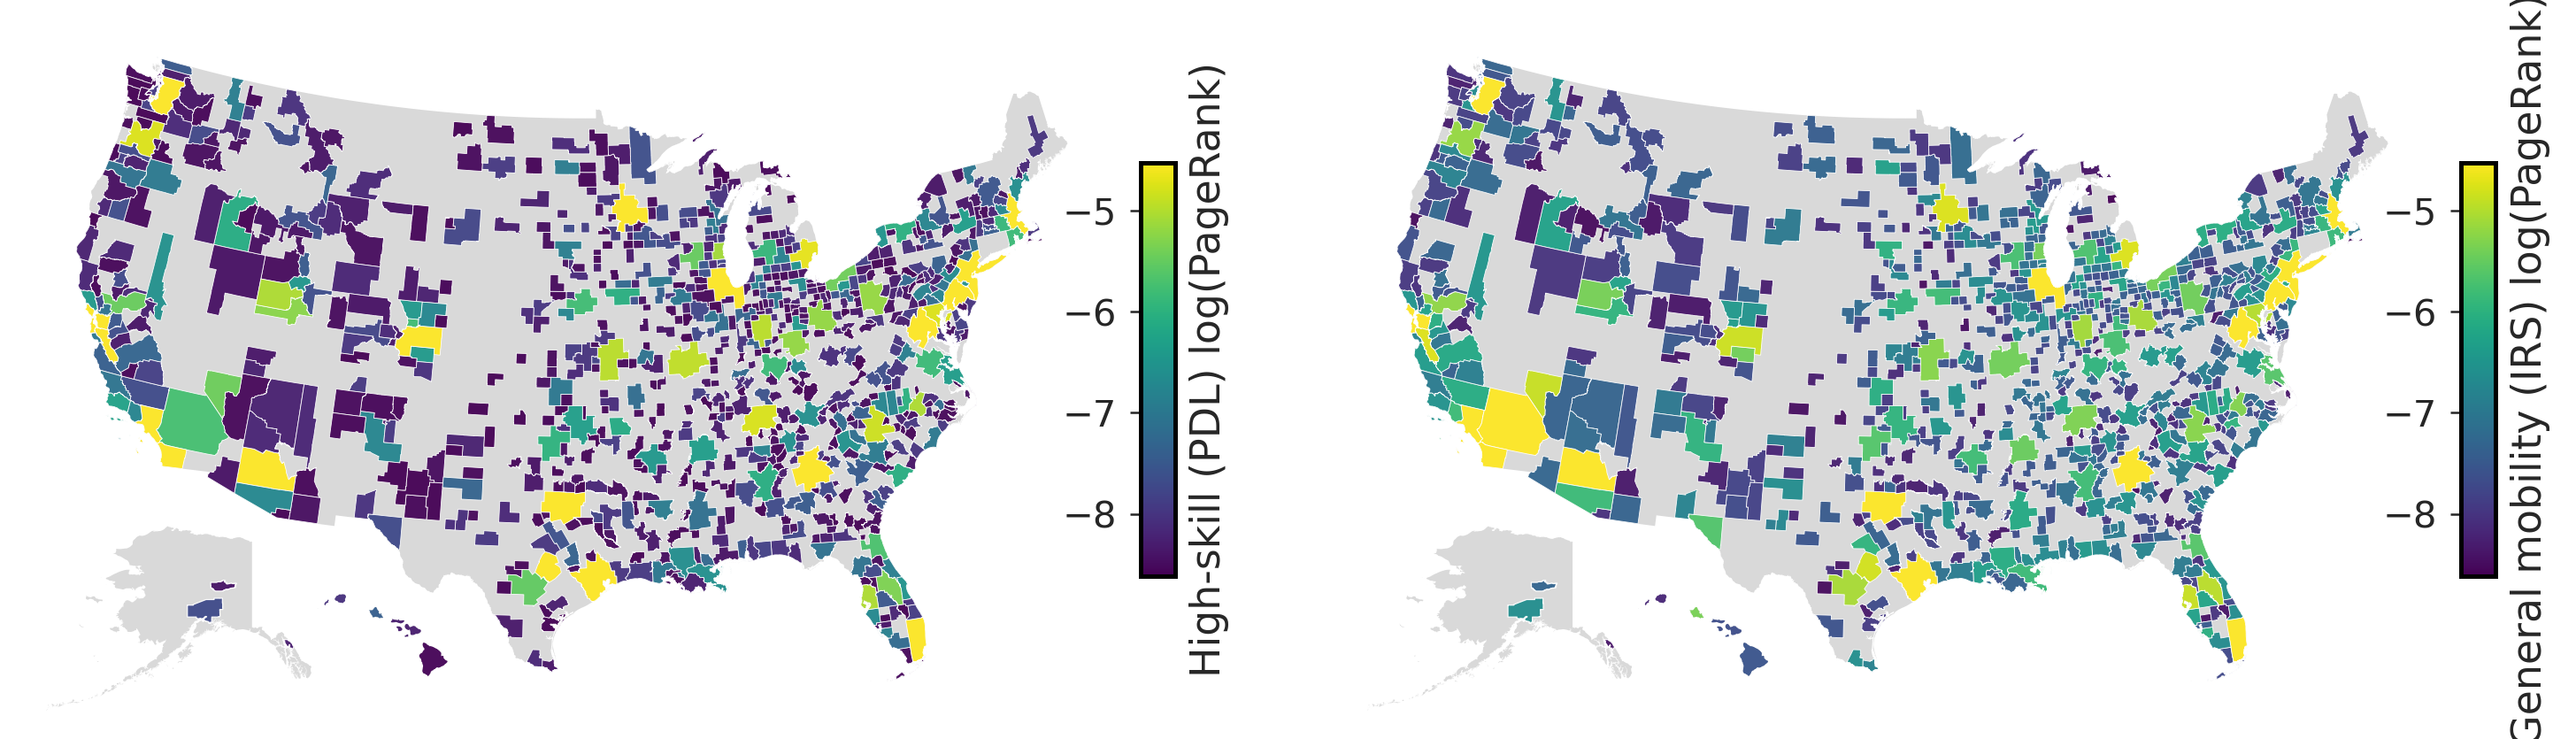

In [22]:
cbsa_ak_hi = ["11260", "21820", "27940", "16220", "28540", "46520", "27980", "25900", "28180"]
not_conus = ["02", "15", "72", "78", "60", "66", "69"]

counties_5070 = counties.to_crs("EPSG:5070")
counties_4269 = counties.to_crs("EPSG:4269")
usa = cbsa_agg.to_crs("EPSG:5070")
usa_4269 = cbsa_agg.to_crs("EPSG:4269")

conus = usa[~usa["CBSA"].isin(cbsa_ak_hi)]
alaska = usa_4269[usa_4269["CBSA"].isin(["11260", "21820", "27940", "16220", "28540"])]
hawaii = usa_4269[usa_4269["CBSA"].isin(["46520", "27980", "25900", "28180"])]

conus_counties = counties_5070[~counties_5070["STATEFP"].isin(not_conus)].copy()
alaska_counties = counties_4269[counties_4269["STATEFP"] == "02"].copy()
hawaii_counties = counties_4269[counties_4269["STATEFP"] == "15"].copy()

conus_outline = conus_counties[["geometry"]].dissolve()
alaska_outline = alaska_counties[["geometry"]].dissolve()
hawaii_outline = hawaii_counties[["geometry"]].dissolve()

colors_strong = ["#7f3b08", "#f2c68b", "#fcead6", "#9678d1", "#3f007d"]
strong_puor = mcolors.LinearSegmentedColormap.from_list("StrongPuOr", colors_strong, N=256)

def add_ak_hi_insets(ax, column, cmap, norm):
    ax_ak = inset_axes(ax, width="100%", height="100%", loc="lower left",
                       bbox_to_anchor=(0.00, 0.00, 0.28, 0.28), bbox_transform=ax.transAxes, borderpad=0)
    ax_ak.axis("off")
    alaska_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_ak, zorder=1)
    alaska.plot(column=column, cmap=cmap, norm=norm, linewidth=0.3, edgecolor="white",
               ax=ax_ak, alpha=0.95, zorder=2, missing_kwds={"color": "none"})
    ax_ak.set_xlim(-180, -129)
    ax_ak.set_ylim(51, 72)
    ax_hi = inset_axes(ax, width="100%", height="100%", loc="lower left",
                       bbox_to_anchor=(0.24, 0.02, 0.18, 0.18), bbox_transform=ax.transAxes, borderpad=0)
    ax_hi.axis("off")
    hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi, zorder=1)
    hawaii.plot(column=column, cmap=cmap, norm=norm, linewidth=0, ax=ax_hi, alpha=0.95, zorder=2,
               missing_kwds={"color": "none"})
    ax_hi.set_xlim(-161, -154)
    ax_hi.set_ylim(18, 23)

shared_vmin = np.nanpercentile(np.concatenate([conus["log_pagerank_exp"], conus["log_pagerank_irs"]]), 2)
shared_vmax = np.nanpercentile(np.concatenate([conus["log_pagerank_exp"], conus["log_pagerank_irs"]]), 98)
shared_norm = mpl.colors.Normalize(vmin=shared_vmin, vmax=shared_vmax)
diff_vmax = np.nanpercentile(np.abs(conus["pagerank_logdiff"]), 97)
diff_norm = TwoSlopeNorm(vmin=-diff_vmax, vcenter=0, vmax=diff_vmax)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"wspace": 0.15})
panels = [
    (axes[0], "log_pagerank_exp", "viridis", shared_norm, "High-skill (PDL) log(PageRank)"),
    (axes[1], "log_pagerank_irs", "viridis", shared_norm, "General mobility (IRS) log(PageRank)")
]
for ax, column, cmap, norm, label in panels:
    conus_outline.plot(color="#d9d9d9", linewidth=0, ax=ax, zorder=1)
    conus.plot(column=column, cmap=cmap, norm=norm, linewidth=0.2, edgecolor="white",
              ax=ax, alpha=0.95, zorder=2, missing_kwds={"color": "none"})
    ax.axis("off")
    add_ak_hi_insets(ax, column, cmap, norm)
    sm_cbar = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm_cbar._A = []
    cbar = fig.colorbar(sm_cbar, ax=ax, orientation="vertical", fraction=0.03, pad=0.02, aspect=12)
    cbar.ax.yaxis.set_ticks_position("left")
    cbar.ax.tick_params(labelleft=True, labelright=False)
    cbar.ax.yaxis.set_label_position("right")
    cbar.set_label(label)

plt.savefig(f"{REPO}/fig/si/si_network_comparison_map.pdf", bbox_inches="tight", dpi=300)
print("Saved -> fig/si/si_network_comparison_map.pdf")

In [23]:
rho, p = stats.spearmanr(merged["pagerank_exp"], merged["pagerank_irs"])
print(f"Spearman(exp PageRank, irs PageRank) across {len(merged)} CBSAs: rho={rho:.3f}, p={p:.2e}")

Spearman(exp PageRank, irs PageRank) across 806 CBSAs: rho=0.791, p=4.36e-174


## Section 4 - External validation of high-skill flows vs LEHD J2J

State-level J2J, not CBSAs (due to size constraints).

In [24]:
import glob, gzip

STATE_FIPS = {
   "ak":"02","al":"01","ar":"05","az":"04","ca":"06","co":"08","ct":"09","dc":"11","de":"10",
   "fl":"12","ga":"13","hi":"15","ia":"19","id":"16","il":"17","in":"18","ks":"20","ky":"21",
   "la":"22","ma":"25","md":"24","me":"23","mi":"26","mn":"27","mo":"29","ms":"28","mt":"30",
   "nc":"37","nd":"38","ne":"31","nh":"33","nj":"34","nm":"35","nv":"32","ny":"36","oh":"39",
   "ok":"40","or":"41","pa":"42","ri":"44","sc":"45","sd":"46","tn":"47","tx":"48","ut":"49",
   "va":"51","vt":"50","wa":"53","wi":"55","wv":"54","wy":"56",
}

files = sorted(glob.glob(f"{REPO}/data_loaded/external_validation/lehd_j2j/j2jod_*_se_f_gs_n_oslp_u.csv.gz"))
print(f"Loading {len(files)} state J2J files...")

KEEP_COLS = ["geography", "geography_orig", "education", "year", "quarter", "sex",
            "ownercode", "firmage", "firmsize", "seasonadj", "EE"]
frames = []
for fp in files:
    with gzip.open(fp) as f:
        d = pd.read_csv(f, usecols=KEEP_COLS, dtype=str)
    d["EE"] = pd.to_numeric(d["EE"], errors="coerce")
    d = d[(d["sex"] == "0") & (d["ownercode"] == "A00") & (d["firmage"] == "0") &
         (d["firmsize"] == "0") & (d["seasonadj"] == "U") &
         (d["education"].isin(["E4", "E5"]))]
    frames.append(d)
j2j = pd.concat(frames, ignore_index=True)
print(f"Combined, filtered (sex=total, BA+ education, unadjusted, all firm age/size): {len(j2j)} rows")

j2j["year"] = j2j["year"].astype(int)
j2j_1119 = j2j[(j2j["year"] >= 2011) & (j2j["year"] <= 2019)].copy()
print(f"Restricted to 2011-2019: {len(j2j_1119)} rows")

j2j_od = (j2j_1119.groupby(["geography_orig", "geography"])["EE"].sum().reset_index()
         .rename(columns={"geography_orig": "state_o", "geography": "state_d", "EE": "n_j2j"}))
valid_states = set(STATE_FIPS.values())
j2j_od = j2j_od[j2j_od["state_o"].isin(valid_states) & j2j_od["state_d"].isin(valid_states)]
print(f"Aggregated to {len(j2j_od)} state-pair OD cells, total EE = {j2j_od['n_j2j'].sum():,.0f}")

Loading 51 state J2J files...
Combined, filtered (sex=total, BA+ education, unadjusted, all firm age/size): 991704 rows
Restricted to 2011-2019: 368878 rows
Aggregated to 2601 state-pair OD cells, total EE = 81,816,077


In [25]:
df_win_1119 = df_win[(df_win["next_start_date"] >= "2011-01-01") & (df_win["next_start_date"] <= "2019-12-31")].copy()
df_win_1119["state_o"] = df_win_1119["STCOFIPS"].str[:2]
df_win_1119["state_d"] = df_win_1119["STCOFIPS_next"].str[:2]
exp_od = df_win_1119.groupby(["state_o", "state_d"]).size().reset_index(name="n_exp")
print(f"Our high-skill (exp) state OD, 2011-2019: {len(exp_od)} cells, "
     f"total transitions = {exp_od['n_exp'].sum():,.0f}, N persons = {df_win_1119.PERSON_ID.nunique():,.0f}")

irs_files = []
for yy in ["1112","1213","1314","1415","1516","1617","1718","1819"]:
    fp = f"{REPO}/data_loaded/irs/countyinflow{yy}.csv"
    d = pd.read_csv(fp, dtype=str, encoding="latin1")
    d["n2"] = pd.to_numeric(d["n2"], errors="coerce")
    d = d[~d["y1_statefips"].isin(["96", "97", "98"])]
    d["state_o"] = d["y1_statefips"]
    d["state_d"] = d["y2_statefips"]
    irs_files.append(d.groupby(["state_o", "state_d"])["n2"].sum().reset_index())
irs_od = pd.concat(irs_files).groupby(["state_o", "state_d"])["n2"].sum().reset_index().rename(columns={"n2": "n_irs"})
print(f"Our general-mobility (irs) state OD, 2011-2019 (8 year-pairs summed): {len(irs_od)} cells, "
     f"total = {irs_od['n_irs'].sum():,.0f}")

Our high-skill (exp) state OD, 2011-2019: 2251 cells, total transitions = 162,813, N persons = 111,563
Our general-mobility (irs) state OD, 2011-2019 (8 year-pairs summed): 2312 cells, total = 2,098,373,785


### Marginal correlations

In [26]:
def marginals(od, o_col, d_col, val_col):
    out_ = od.groupby(o_col)[val_col].sum().rename("out")
    in_ = od.groupby(d_col)[val_col].sum().rename("in")
    return pd.concat([out_, in_], axis=1).fillna(0)

m_exp = marginals(exp_od, "state_o", "state_d", "n_exp")
m_irs = marginals(irs_od, "state_o", "state_d", "n_irs")
m_j2j = marginals(j2j_od, "state_o", "state_d", "n_j2j")

def corr_row(ours, theirs, label):
    both = pd.concat([ours, theirs], axis=1, keys=["ours", "theirs"]).dropna()
    both = both[(both.iloc[:, 0] > 0) & (both.iloc[:, 1] > 0)]
    lx = np.log10(both.iloc[:, 0] + 1)
    ly = np.log10(both.iloc[:, 1] + 1)
    pear = stats.pearsonr(lx, ly)
    spear = stats.spearmanr(both.iloc[:, 0], both.iloc[:, 1])
    X = sm.add_constant(lx)
    mdl = sm.OLS(ly, X).fit()
    slope = mdl.params.iloc[1]
    ci = mdl.conf_int().iloc[1]
    return dict(comparison=label, pearson_loglog=pear[0], spearman=spear.correlation,
               slope=slope, slope_ci_lo=ci[0], slope_ci_hi=ci[1], n=len(both))

rows = []
rows.append(corr_row(m_exp["out"], m_j2j["out"], "exp_out vs J2J_out"))
rows.append(corr_row(m_exp["in"], m_j2j["in"], "exp_in vs J2J_in"))
rows.append(corr_row(m_irs["out"], m_j2j["out"], "irs_out vs J2J_out"))
rows.append(corr_row(m_irs["in"], m_j2j["in"], "irs_in vs J2J_in"))
marg_df = pd.DataFrame(rows)
print(marg_df.round(4).to_string(index=False))
marg_df.to_csv(f"{REPO}/data_generated/representativeness/j2j_validation.csv", index=False)

        comparison  pearson_loglog  spearman  slope  slope_ci_lo  slope_ci_hi  n
exp_out vs J2J_out          0.9262    0.9230 0.6240       0.5511       0.6969 51
  exp_in vs J2J_in          0.9272    0.9297 0.5909       0.5224       0.6595 51
irs_out vs J2J_out          0.9790    0.9833 0.9144       0.8597       0.9691 51
  irs_in vs J2J_in          0.9771    0.9821 0.9162       0.8589       0.9734 51


### Scatter + 45-degree line, on shares of grand total

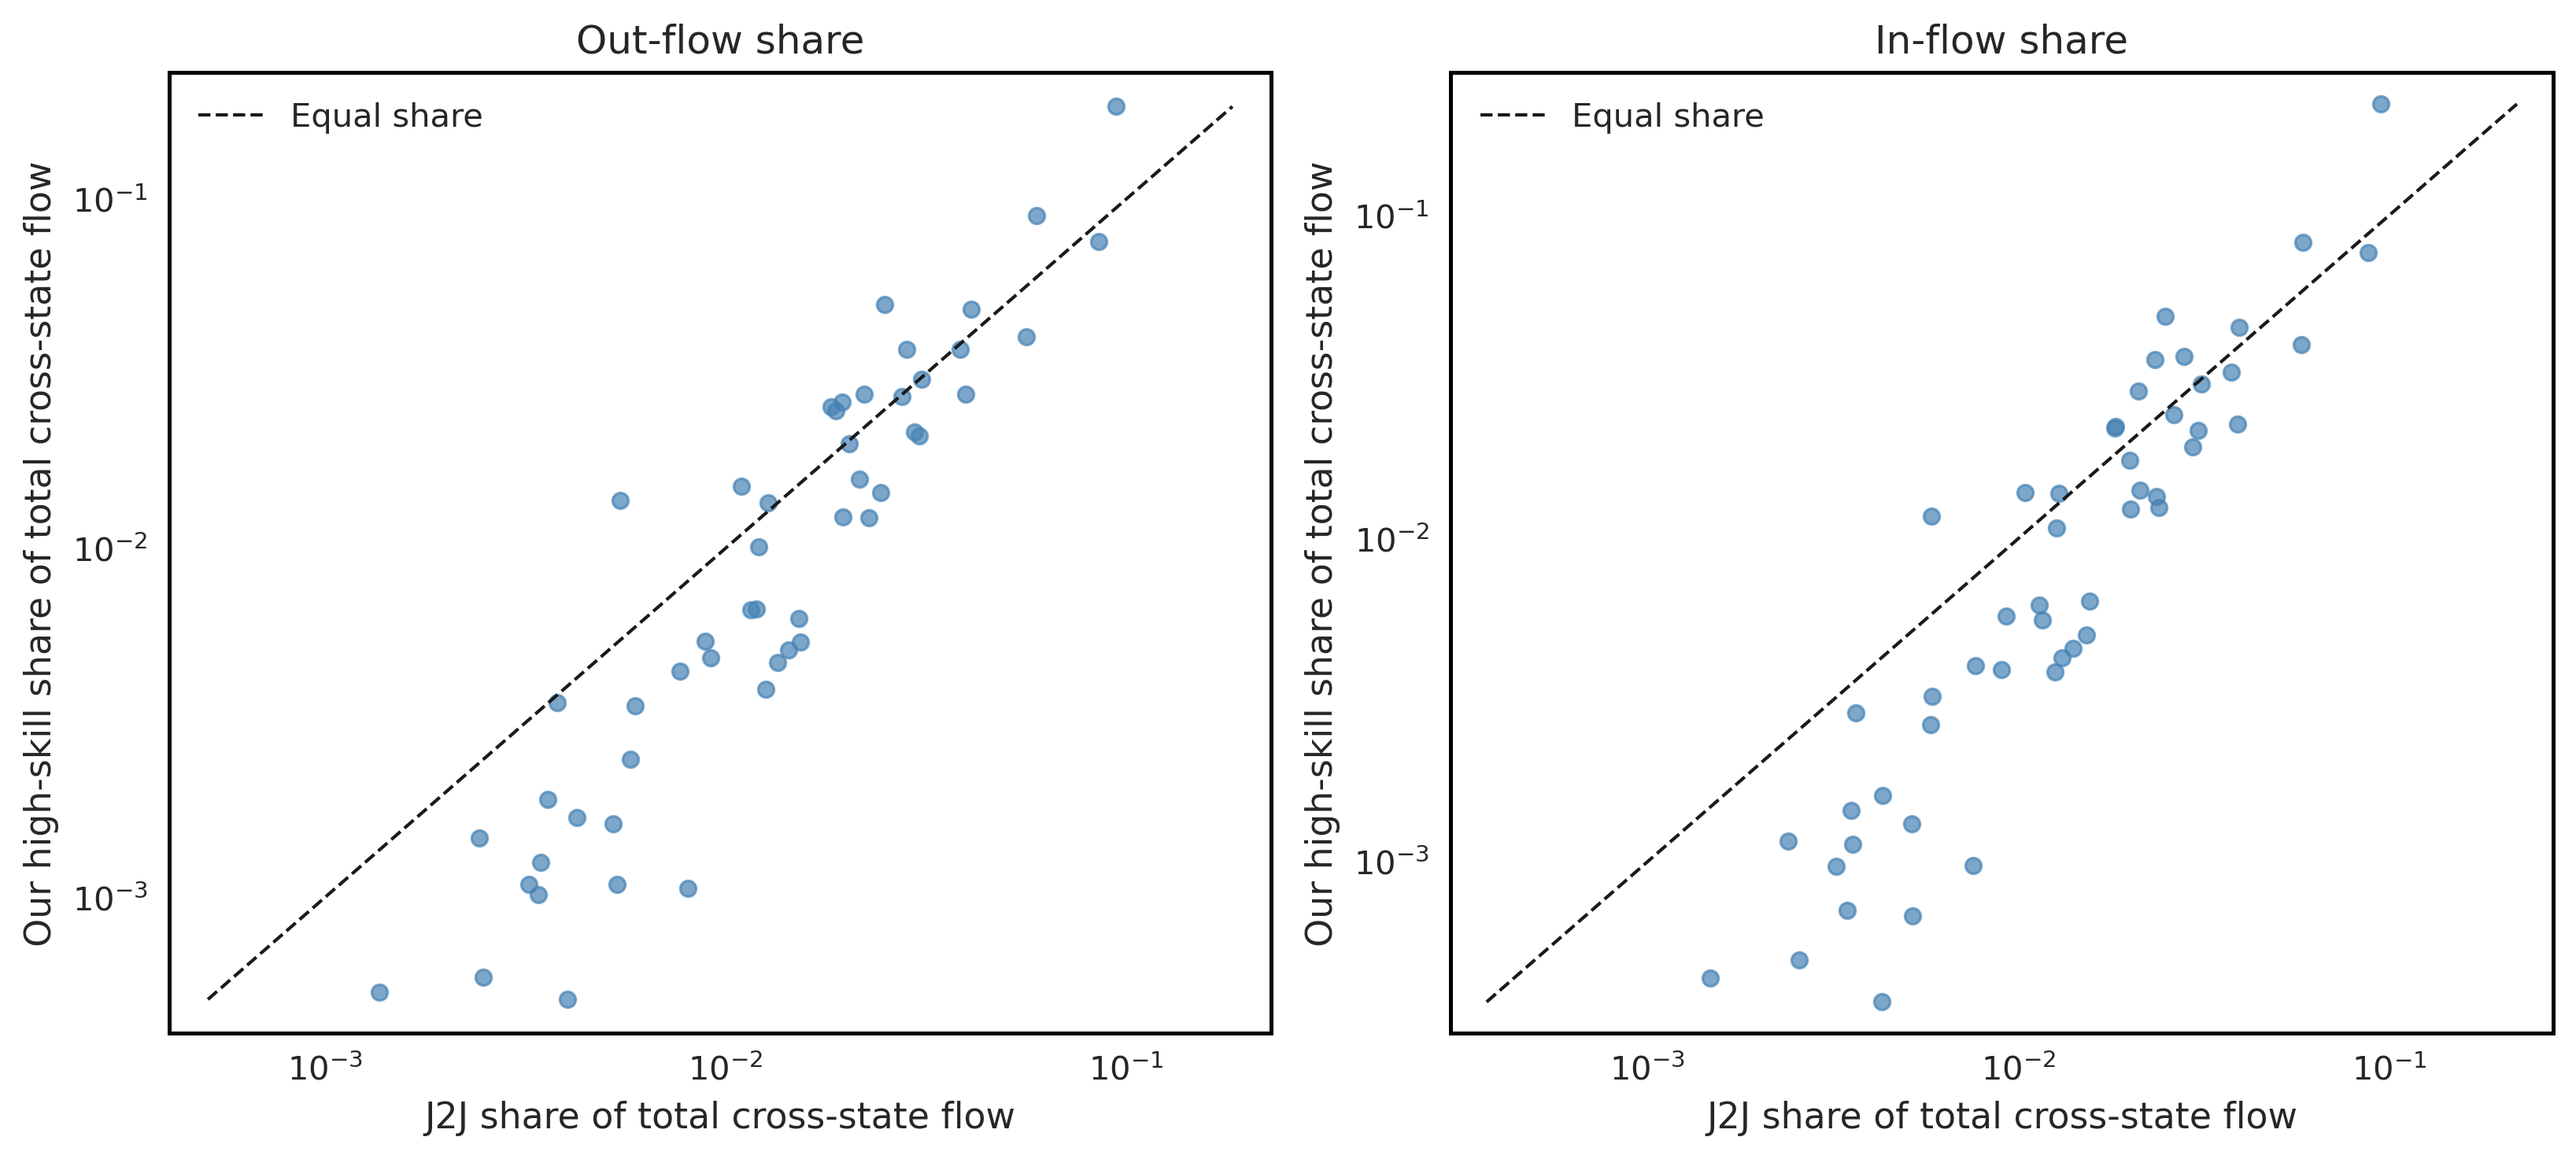

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, (ours, theirs, lbl) in zip(axes, [
    (m_exp["out"], m_j2j["out"], "Out-flow share"),
    (m_exp["in"],  m_j2j["in"],  "In-flow share"),
]):

    # Normalize BEFORE restricting to common positive states
    s_ours_all = ours / ours.sum()
    s_j2j_all  = theirs / theirs.sum()

    both = pd.concat(
        [s_ours_all, s_j2j_all],
        axis=1,
        keys=["ours", "j2j"]
    ).dropna()

    both = both[(both["ours"] > 0) & (both["j2j"] > 0)]

    ax.scatter(
        both["j2j"],
        both["ours"],
        alpha=0.7,
        color="steelblue"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    lo = min(both["ours"].min(), both["j2j"].min())
    hi = max(both["ours"].max(), both["j2j"].max())

    ax.plot(
        [lo, hi], [lo, hi],
        "k--", lw=1,
        label="Equal share"
    )

    ax.set_xlim(lo * 0.8, hi * 1.25)
    ax.set_ylim(lo * 0.8, hi * 1.25)

    ax.set_xlabel("J2J share of total cross-state flow")
    ax.set_ylabel("Our high-skill share of total cross-state flow")
    ax.set_title(lbl)

    ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(
    f"{REPO}/fig/si/si_represent_marginals.pdf",
    bbox_inches="tight"
)

### Dyadic comparison, best-effort

Cross-state dyads: 2552 possible, 2199 with positive flow on both sides (86.2%)
Share of our positive-flow dyads with zero J2J flow: 0.1%
Spearman on positive-positive dyads (n=2199): rho=0.807, p=0.00e+00
Of our top-500 dyads by volume, 500 (100.0%) have nonzero J2J flow
Saved -> fig/si/si_represent_dyads.pdf

Node coverage: our network touches 53 states, J2J touches 51 states


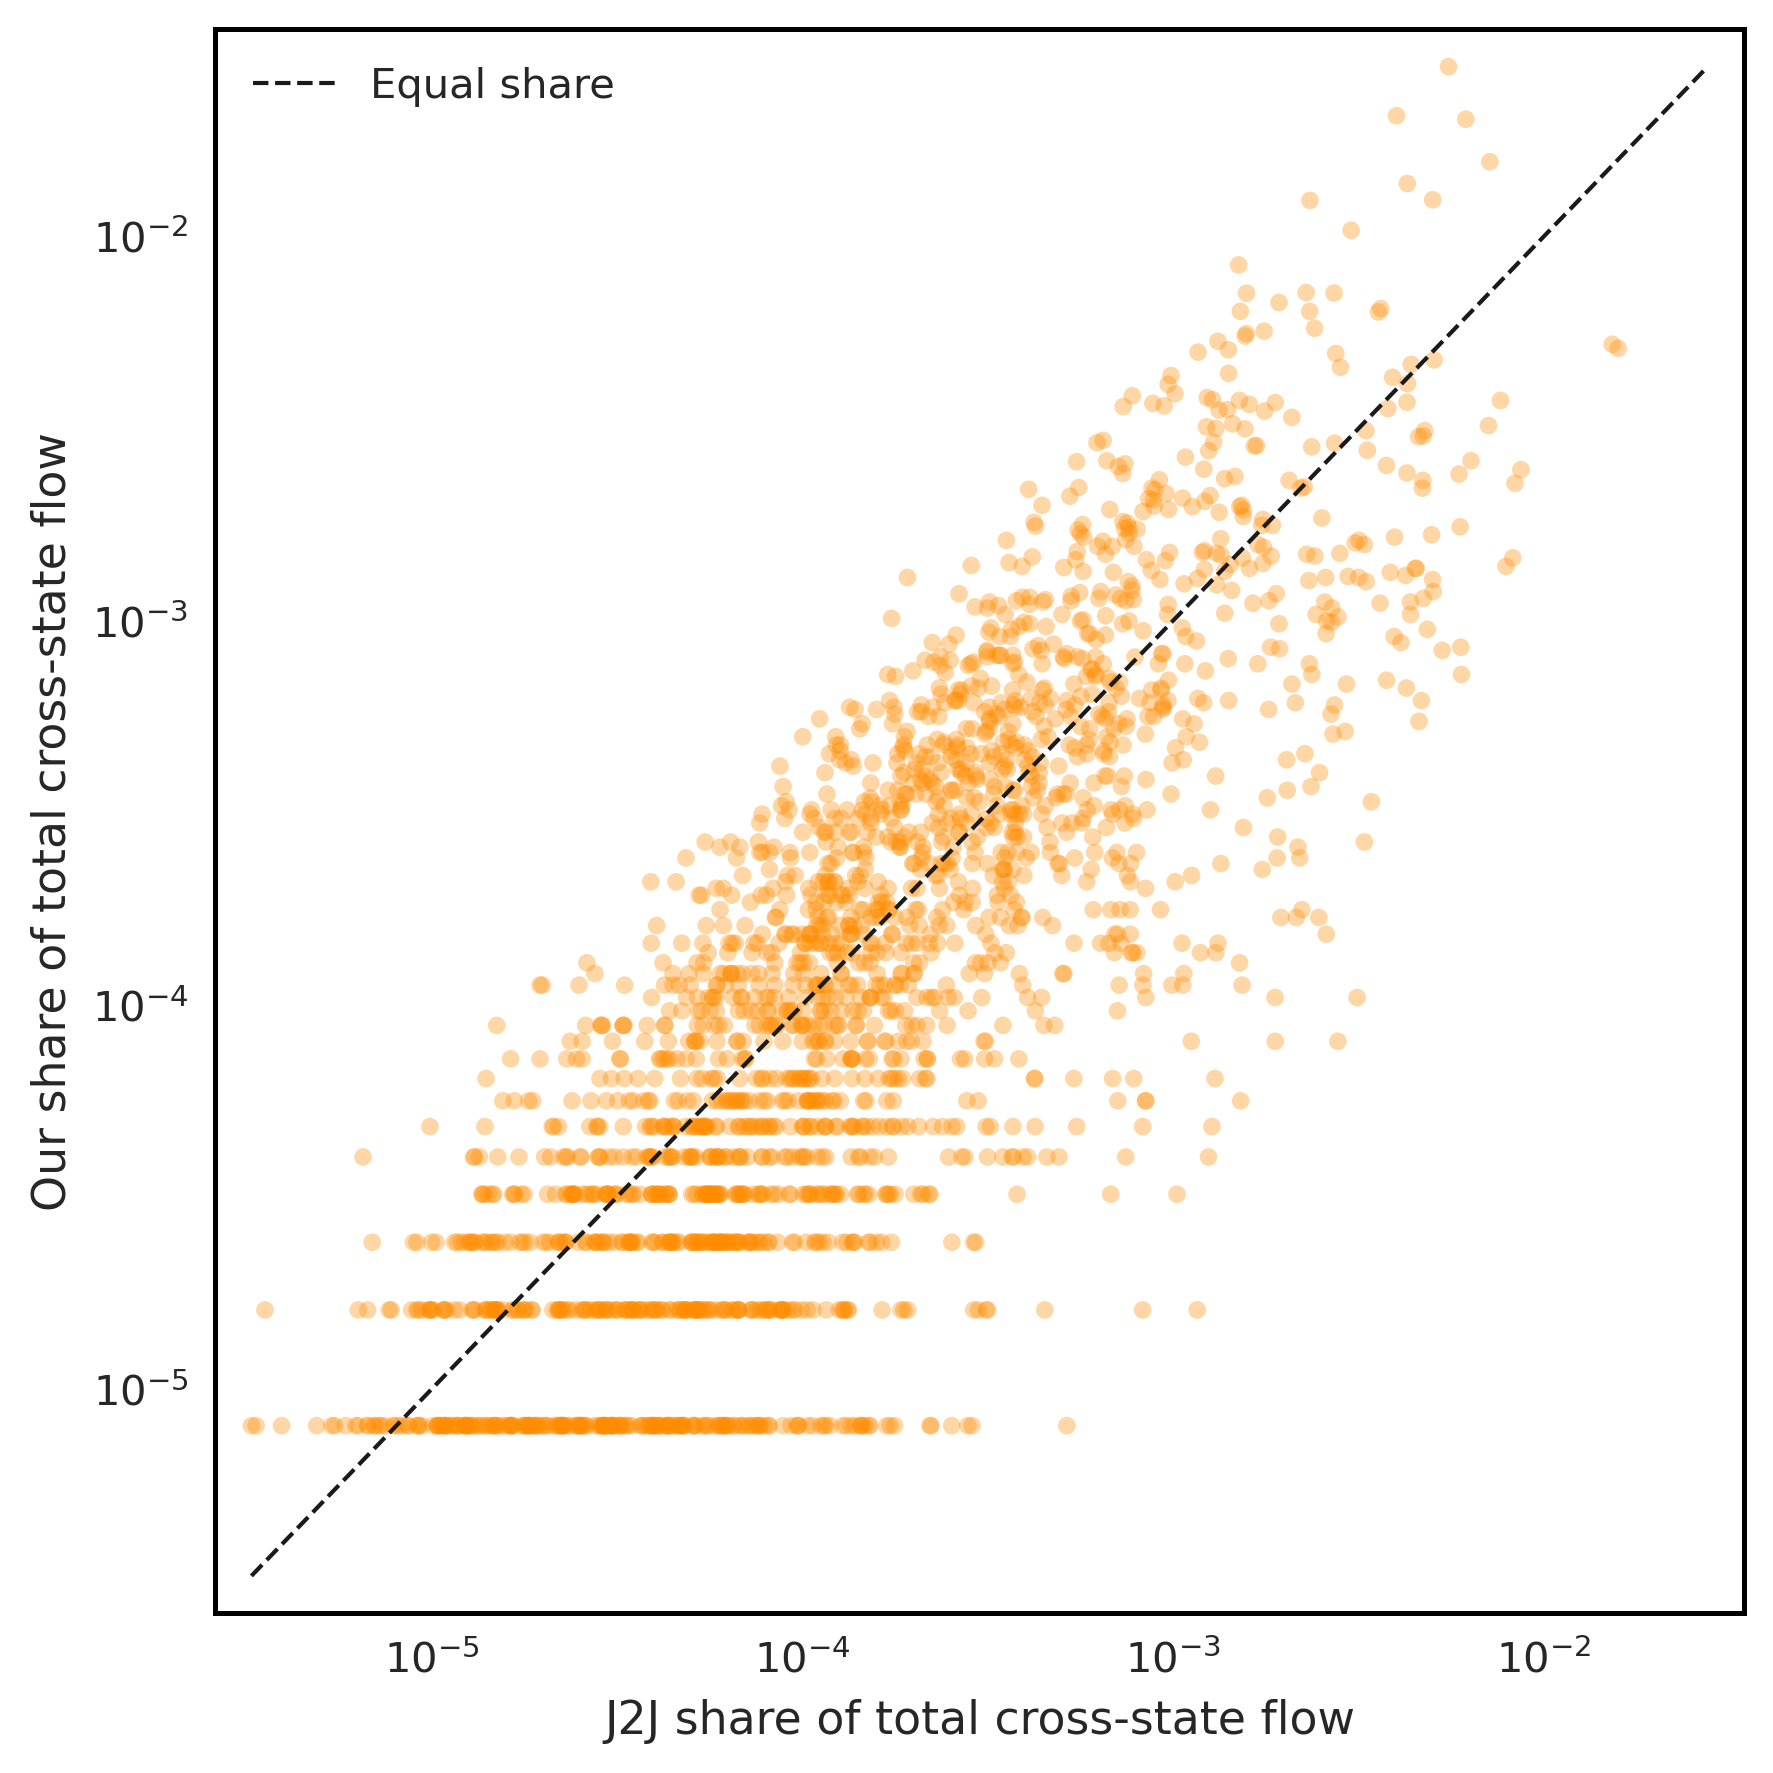

In [28]:
dyad = exp_od.merge(j2j_od, on=["state_o", "state_d"], how="outer").fillna(0)
dyad = dyad[dyad["state_o"] != dyad["state_d"]]
pos_both = (dyad["n_exp"] > 0) & (dyad["n_j2j"] > 0)
print(f"Cross-state dyads: {len(dyad)} possible, {pos_both.sum()} with positive flow on both sides "
     f"({pos_both.mean():.1%})")
zero_j2j_share = ((dyad["n_exp"] > 0) & (dyad["n_j2j"] == 0)).sum() / (dyad["n_exp"] > 0).sum()
print(f"Share of our positive-flow dyads with zero J2J flow: {zero_j2j_share:.1%}")

sub = dyad[pos_both]
rho_dyad, p_dyad = stats.spearmanr(sub["n_exp"], sub["n_j2j"])
print(f"Spearman on positive-positive dyads (n={len(sub)}): rho={rho_dyad:.3f}, p={p_dyad:.2e}")

dyad_top = dyad.nlargest(500, "n_exp")
jacc_num = (dyad_top["n_j2j"] > 0).sum()
print(f"Of our top-500 dyads by volume, {jacc_num} ({jacc_num/500:.1%}) have nonzero J2J flow")

# Shares relative to ALL cross-state flow in each dataset
total_exp = dyad["n_exp"].sum()
total_j2j = dyad["n_j2j"].sum()

s = dyad.loc[pos_both].copy()
s["share_exp"] = s["n_exp"] / total_exp
s["share_j2j"] = s["n_j2j"] / total_j2j

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    s["share_j2j"],
    s["share_exp"],
    alpha=0.35,
    s=18,
    color="darkorange",
    edgecolors="none"
)

ax.set_xscale("log")
ax.set_yscale("log")

lo = min(s["share_exp"].min(), s["share_j2j"].min())
hi = max(s["share_exp"].max(), s["share_j2j"].max())

ax.plot(
    [lo, hi], [lo, hi],
    "k--", lw=1,
    label="Equal share"
)

ax.set_xlim(lo * 0.8, hi * 1.25)
ax.set_ylim(lo * 0.8, hi * 1.25)

ax.set_xlabel("J2J share of total cross-state flow")
ax.set_ylabel("Our share of total cross-state flow")

ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(f"{REPO}/fig/si/si_represent_dyads.pdf", bbox_inches="tight")
print("Saved -> fig/si/si_represent_dyads.pdf")

print(f"\nNode coverage: our network touches {len(set(exp_od.state_o)|set(exp_od.state_d))} states, "
     f"J2J touches {len(set(j2j_od.state_o)|set(j2j_od.state_d))} states")

General-mobility marginals correlate at r=0.98 with J2J; high-skill marginals at r=0.93; dyadic Spearman=0.81 on 2,199 positive-positive state pairs; 100% of our top-500 dyads by volume have nonzero J2J flow.

### Additionally - industry-crossed J2J

**J2J table** (single-geography job-to-job counts) with **21 NAICS industry supersectors** (the OD extract only had `industry='00'` total). Age and race/ethnicity columns are present but fixed to "all" in this extract. Coverage: state + national level only (same ceiling as above), single year 2019.

In [29]:
FP = f"{REPO}/data_loaded/external_validation/j2j_9676512c4e6eac506ce929e12762bd9c.csv"
USECOLS = ["seasonadj", "geo_level", "geography", "ind_level", "industry", "ownercode",
          "sex", "agegrp", "education", "firmage", "firmsize", "year", "quarter", "J2J"]
j2j_ind = pd.read_csv(FP, usecols=USECOLS, dtype=str)
j2j_ind["J2J"] = pd.to_numeric(j2j_ind["J2J"], errors="coerce")
print(f"Loaded {len(j2j_ind):,} rows")

mask = ((j2j_ind["sex"] == "0") & (j2j_ind["ownercode"] == "A00") & (j2j_ind["firmage"] == "0") &
       (j2j_ind["firmsize"] == "0") & (j2j_ind["seasonadj"] == "U") & (j2j_ind["geo_level"] == "S") &
       (j2j_ind["education"].isin(["E4", "E5"])))
d_ind = j2j_ind[mask].copy()
print(f"Filtered (state-level, sex=total, BA+ education, unadjusted, all firm age/size): {len(d_ind)} rows")

total_ind = d_ind[d_ind["industry"] == "00"].groupby("geography")["J2J"].sum()
print(f"Total-industry (NAICS '00') state J2J, 2019, BA+: {len(total_ind)} states, sum={total_ind.sum():,.0f}")

Loaded 10,603,654 rows
Filtered (state-level, sex=total, BA+ education, unadjusted, all firm age/size): 1123818 rows
Total-industry (NAICS '00') state J2J, 2019, BA+: 50 states, sum=27,885,721


In [30]:
df_win_2019 = df_win[(df_win["next_start_date"] >= "2019-01-01") & (df_win["next_start_date"] <= "2019-12-31")].copy()
df_win_2019["state_o"] = df_win_2019["STCOFIPS"].str[:2]
df_win_2019["state_d"] = df_win_2019["STCOFIPS_next"].str[:2]
our_2019 = pd.concat([
    df_win_2019.groupby("state_o").size().rename("out"),
    df_win_2019.groupby("state_d").size().rename("in"),
], axis=1).fillna(0)
our_2019["total"] = our_2019["out"] + our_2019["in"]
print(f"Our high-skill network, 2019 only: {df_win_2019.PERSON_ID.nunique()} persons, "
     f"{len(df_win_2019)} transitions, {len(our_2019)} states touched")

rows = []
for naics, label in [("00", "All industries"), ("54", "Professional/Scientific/Technical"),
                     ("51", "Information"), ("52", "Finance & Insurance"),
                     ("62", "Health Care & Social Assistance")]:
    sub = d_ind[d_ind["industry"] == naics].groupby("geography")["J2J"].sum()
    both = pd.concat([our_2019["total"], sub.rename("j2j")], axis=1).dropna()
    both = both[(both["total"] > 0) & (both["j2j"] > 0)]
    if len(both) < 5:
        continue
    lx = np.log10(both["total"] + 1)
    ly = np.log10(both["j2j"] + 1)
    pear = stats.pearsonr(lx, ly)
    spear = stats.spearmanr(both["total"], both["j2j"])
    rows.append(dict(industry=f"{naics} ({label})", pearson_loglog=pear[0], spearman=spear.correlation, n=len(both)))
ind_corr = pd.DataFrame(rows)
print(ind_corr.round(4).to_string(index=False))
ind_corr.to_csv(f"{REPO}/data_generated/representativeness/industry_flows.csv", index=False)

Our high-skill network, 2019 only: 18222 persons, 18945 transitions, 51 states touched
                              industry  pearson_loglog  spearman  n
                   00 (All industries)          0.8974    0.9053 50
54 (Professional/Scientific/Technical)          0.9610    0.9686 50
                      51 (Information)          0.9473    0.9584 50
              52 (Finance & Insurance)          0.9115    0.9247 50
  62 (Health Care & Social Assistance)          0.8767    0.8928 50


## Consolidated findings

In [31]:
summary = pd.DataFrame([
    dict(section="Map comparison", metric="Spearman(exp PageRank, irs PageRank), 806 CBSAs", value="0.791"),
    dict(section="Map comparison", metric="Most high-skill-centrality-exceeds-general CBSA", value="San Francisco-Oakland-Fremont, CA (logdiff=+1.61)"),
    dict(section="Map comparison", metric="Most general-exceeds-high-skill CBSA", value="El Paso, TX (logdiff=-2.06)"),
    dict(section="Occupational", metric="OES employment unmatched to Job Zone map", value="30.7% of national detailed employment -- PARTIAL benchmark"),
    dict(section="Occupational", metric="Computer & Math: our share vs OES JZ4-5 share", value="27.6% vs 4.6% (6.0x overrepresented)"),
    dict(section="Occupational", metric="Healthcare Practitioners: our share vs OES JZ4-5", value="1.5% vs 13.8% (0.11x underrepresented)"),
    dict(section="Occupational", metric="soc_broad groups absent from OES JZ4-5 entirely", value="6 of 21 (become zero rows)"),
    dict(section="Geographic", metric="Pearson(log persons, log BA+ population), 812 CBSAs", value="0.907"),
    dict(section="Geographic", metric="Log-log slope (persons on BA+ population)", value="0.736 [0.712, 0.760]"),
    dict(section="Geographic", metric="Most over-covered large CBSA", value="San Jose-Sunnyvale-Santa Clara, CA (residual=+0.73)"),
    dict(section="Geographic", metric="PDL persons per 1,000 BA+ adults", value="median 0.67, p10=0.20, p90=1.98"),
    dict(section="Demographic", metric="Base A (age field) missing share", value="32.0%"),
    dict(section="Demographic", metric="Base B (graduation proxy) missing share", value="27.1%"),
    dict(section="Demographic", metric="Spearman(Base A, Base B) on overlap, n=18,517", value="0.010 (p=0.156, NOT significantly correlated)"),
    dict(section="Demographic", metric="18-34 share: ours (both bases) vs ACS BA+", value="~0.79-0.82 vs 0.27 -- sample skews heavily young"),
    dict(section="Flow Validation", metric="Marginal: our high-skill out-flow vs J2J, log-log Pearson", value="0.926"),
    dict(section="Flow Validation", metric="Marginal: our general-mobility out-flow vs J2J, log-log Pearson", value="0.979"),
    dict(section="Flow Validation", metric="Dyadic Spearman, 2,199 positive-positive state pairs", value="0.807"),
    dict(section="Flow Validation", metric="Our top-500 dyads with nonzero J2J flow", value="100.0%"),
    dict(section="Flow Validation", metric="Resolution actually validated", value="STATE, not CBSA (see limitations)"),
    dict(section="Flow Validation", metric="Industry addendum: our 2019 state dist. vs Professional/Tech J2J", value="r=0.961 vs r=0.897 all-industries baseline"),
])
summary.to_csv(f"{REPO}/data_generated/representativeness/consolidated_findings.csv", index=False)